In [1]:
!{sys.executable} -m pip install matplotlib pandas Pillow datasets

/bin/bash: line 1: {sys.executable}: command not found


In [2]:
from datasets import load_dataset
from PIL import Image
import json
import pandas as pd
import matplotlib.pyplot as plt

/home/matrix/.pyenv/versions/3.10.18/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
dataset = load_dataset("naver-clova-ix/cord-v2")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 800
    })
    validation: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
    test: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
})


In [4]:
print("Train      :", len(dataset["train"]))
print("Validation :", len(dataset["validation"]))
print("Test       :", len(dataset["test"]))
print("Total      :", sum(len(dataset[x]) for x in dataset))

Train      : 800
Validation : 100
Test       : 100
Total      : 1000


In [5]:
print(dataset["train"].features)

{'image': Image(mode=None, decode=True), 'ground_truth': Value('string')}


In [6]:
sample = dataset["train"][0]

print(sample.keys())

dict_keys(['image', 'ground_truth'])


Image size: (864, 1296)
Image mode: RGB


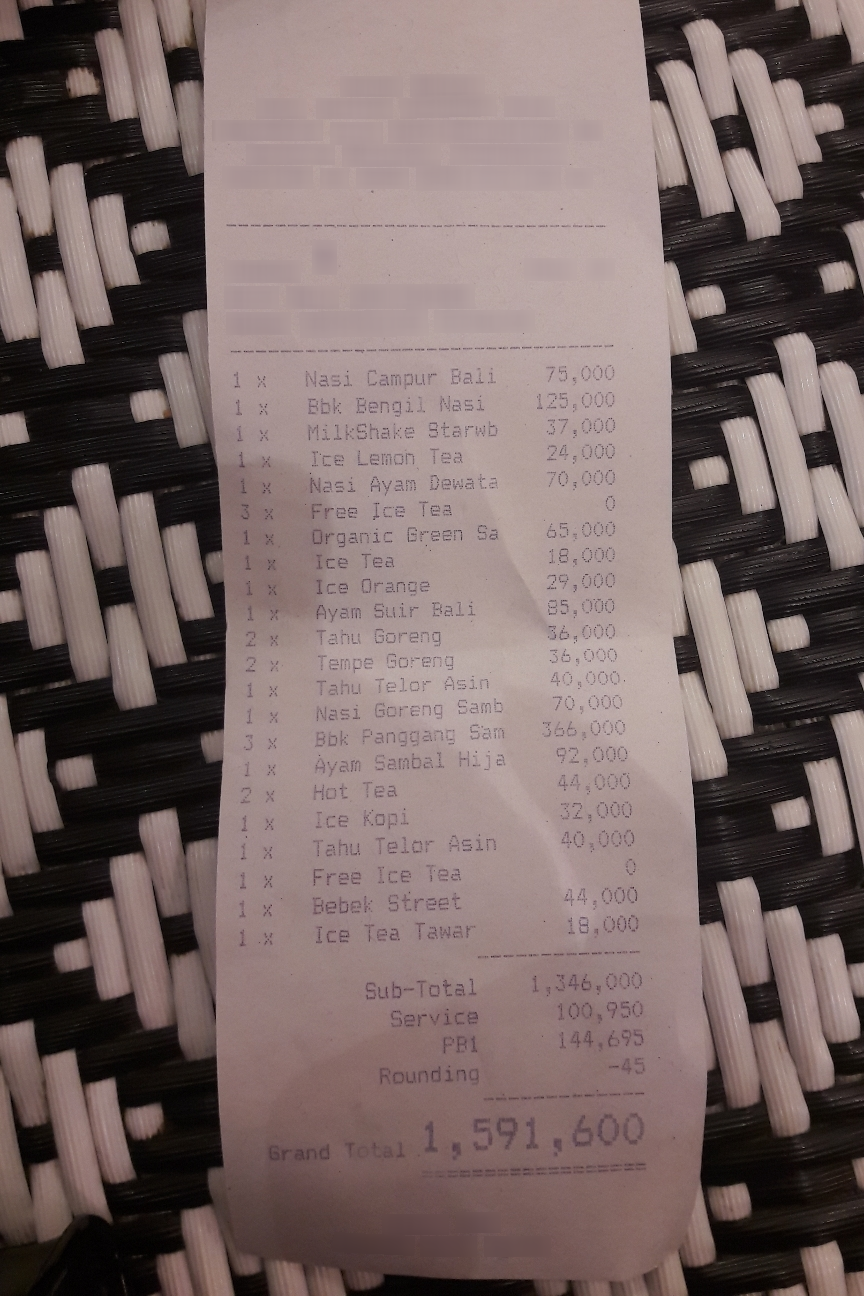

In [7]:
image = sample["image"]

print("Image size:", image.size)
print("Image mode:", image.mode)

display(image)

In [8]:
ground_truth = sample["ground_truth"]

print(type(ground_truth))
print(ground_truth)

<class 'str'>
{"gt_parse": {"menu": [{"nm": "Nasi Campur Bali", "cnt": "1 x", "price": "75,000"}, {"nm": "Bbk Bengil Nasi", "cnt": "1 x", "price": "125,000"}, {"nm": "MilkShake Starwb", "cnt": "1 x", "price": "37,000"}, {"nm": "Ice Lemon Tea", "cnt": "1 x", "price": "24,000"}, {"nm": "Nasi Ayam Dewata", "cnt": "1 x", "price": "70,000"}, {"nm": "Free Ice Tea", "cnt": "3 x", "price": "0"}, {"nm": "Organic Green Sa", "cnt": "1 x", "price": "65,000"}, {"nm": "Ice Tea", "cnt": "1 x", "price": "18,000"}, {"nm": "Ice Orange", "cnt": "1 x", "price": "29,000"}, {"nm": "Ayam Suir Bali", "cnt": "1 x", "price": "85,000"}, {"nm": "Tahu Goreng", "cnt": "2 x", "price": "36,000"}, {"nm": "Tempe Goreng", "cnt": "2 x", "price": "36,000"}, {"nm": "Tahu Telor Asin", "cnt": "1 x", "price": "40,000."}, {"nm": "Nasi Goreng Samb", "cnt": "1 x", "price": "70,000"}, {"nm": "Bbk Panggang Sam", "cnt": "3 x", "price": "366,000"}, {"nm": "Ayam Sambal Hija", "cnt": "1 x", "price": "92,000"}, {"nm": "Hot Tea", "cnt":

In [9]:
if isinstance(ground_truth, str):
    ground_truth = json.loads(ground_truth)

gt_parse = ground_truth["gt_parse"]

print(json.dumps(gt_parse, indent=2, ensure_ascii=False))

{
  "menu": [
    {
      "nm": "Nasi Campur Bali",
      "cnt": "1 x",
      "price": "75,000"
    },
    {
      "nm": "Bbk Bengil Nasi",
      "cnt": "1 x",
      "price": "125,000"
    },
    {
      "nm": "MilkShake Starwb",
      "cnt": "1 x",
      "price": "37,000"
    },
    {
      "nm": "Ice Lemon Tea",
      "cnt": "1 x",
      "price": "24,000"
    },
    {
      "nm": "Nasi Ayam Dewata",
      "cnt": "1 x",
      "price": "70,000"
    },
    {
      "nm": "Free Ice Tea",
      "cnt": "3 x",
      "price": "0"
    },
    {
      "nm": "Organic Green Sa",
      "cnt": "1 x",
      "price": "65,000"
    },
    {
      "nm": "Ice Tea",
      "cnt": "1 x",
      "price": "18,000"
    },
    {
      "nm": "Ice Orange",
      "cnt": "1 x",
      "price": "29,000"
    },
    {
      "nm": "Ayam Suir Bali",
      "cnt": "1 x",
      "price": "85,000"
    },
    {
      "nm": "Tahu Goreng",
      "cnt": "2 x",
      "price": "36,000"
    },
    {
      "nm": "Tempe Goreng",
      "

In [10]:
print("Annotation fields:")

for key in gt_parse.keys():
    print("-", key)

Annotation fields:
- menu
- sub_total
- total


In [11]:
menu = gt_parse.get("menu", [])

print("Number of menu items:", len(menu))

for i, item in enumerate(menu, 1):
    print(f"\nItem {i}")
    print("Name     :", item.get("nm"))
    print("Quantity :", item.get("cnt"))
    print("Price    :", item.get("price"))

Number of menu items: 22

Item 1
Name     : Nasi Campur Bali
Quantity : 1 x
Price    : 75,000

Item 2
Name     : Bbk Bengil Nasi
Quantity : 1 x
Price    : 125,000

Item 3
Name     : MilkShake Starwb
Quantity : 1 x
Price    : 37,000

Item 4
Name     : Ice Lemon Tea
Quantity : 1 x
Price    : 24,000

Item 5
Name     : Nasi Ayam Dewata
Quantity : 1 x
Price    : 70,000

Item 6
Name     : Free Ice Tea
Quantity : 3 x
Price    : 0

Item 7
Name     : Organic Green Sa
Quantity : 1 x
Price    : 65,000

Item 8
Name     : Ice Tea
Quantity : 1 x
Price    : 18,000

Item 9
Name     : Ice Orange
Quantity : 1 x
Price    : 29,000

Item 10
Name     : Ayam Suir Bali
Quantity : 1 x
Price    : 85,000

Item 11
Name     : Tahu Goreng
Quantity : 2 x
Price    : 36,000

Item 12
Name     : Tempe Goreng
Quantity : 2 x
Price    : 36,000

Item 13
Name     : Tahu Telor Asin
Quantity : 1 x
Price    : 40,000.

Item 14
Name     : Nasi Goreng Samb
Quantity : 1 x
Price    : 70,000

Item 15
Name     : Bbk Panggang Sam
Quant

In [12]:
menu_df = pd.DataFrame(menu)

menu_df

,nm,cnt,price
0,Nasi Campur Bali,1 x,"75,000"
1,Bbk Bengil Nasi,1 x,"125,000"
2,MilkShake Starwb,1 x,"37,000"
3,Ice Lemon Tea,1 x,"24,000"
4,Nasi Ayam Dewata,1 x,"70,000"
5,Free Ice Tea,3 x,0
6,Organic Green Sa,1 x,"65,000"
7,Ice Tea,1 x,"18,000"
8,Ice Orange,1 x,"29,000"
9,Ayam Suir Bali,1 x,"85,000"


In [13]:
for i in range(5):
    sample = dataset["train"][i]

    gt = sample["ground_truth"]

    if isinstance(gt, str):
        gt = json.loads(gt)

    parsed = gt["gt_parse"]

    print(f"\n========== SAMPLE {i} ==========")
    print("Fields:", list(parsed.keys()))
    print("Menu items:", len(parsed.get("menu", [])))


========== SAMPLE 0 ==========
Fields: ['menu', 'sub_total', 'total']
Menu items: 22

========== SAMPLE 1 ==========
Fields: ['menu', 'sub_total', 'total']
Menu items: 6

========== SAMPLE 2 ==========
Fields: ['menu', 'sub_total', 'total']
Menu items: 5

========== SAMPLE 3 ==========
Fields: ['menu', 'sub_total', 'total']
Menu items: 3

========== SAMPLE 4 ==========
Fields: ['menu', 'sub_total', 'total']
Menu items: 4


In [14]:
from collections import Counter

field_counter = Counter()

for sample in dataset["train"]:
    gt = sample["ground_truth"]

    if isinstance(gt, str):
        gt = json.loads(gt)

    parsed = gt.get("gt_parse", {})

    for field in parsed.keys():
        field_counter[field] += 1

print(field_counter)

Counter({'menu': 800, 'total': 798, 'sub_total': 548, 'void_menu': 1})


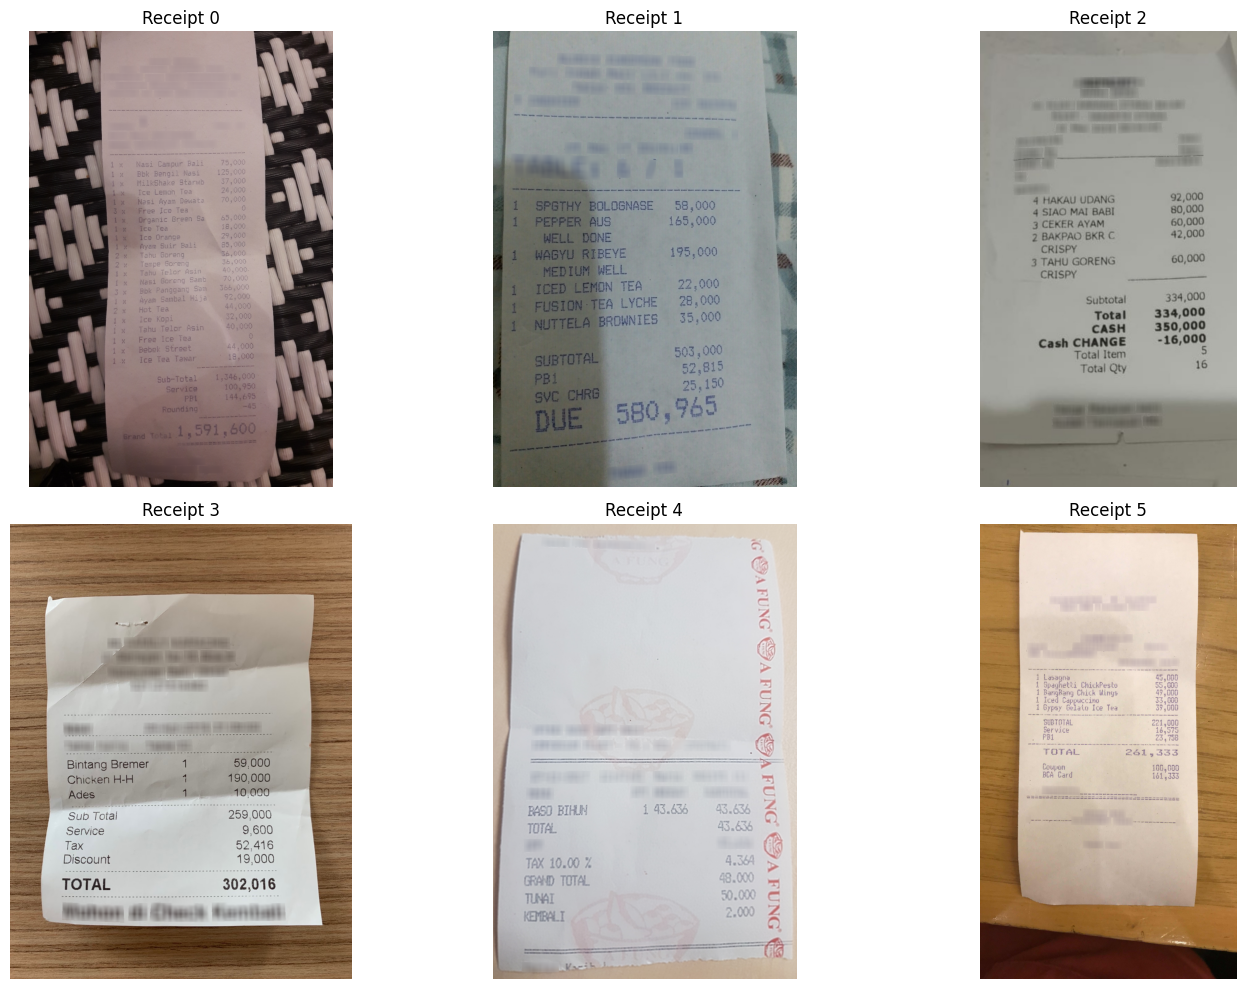

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flat):
    image = dataset["train"][i]["image"]
    ax.imshow(image)
    ax.set_title(f"Receipt {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Show one example for every annotation field

field_examples = {}

for sample in dataset["train"]:
    gt = sample["ground_truth"]

    if isinstance(gt, str):
        gt = json.loads(gt)

    parsed = gt.get("gt_parse", {})

    for field, value in parsed.items():
        if field not in field_examples:
            field_examples[field] = value

print("Field examples:\n")

for field, value in field_examples.items():
    print("=" * 60)
    print("FIELD:", field)
    print(json.dumps(value, indent=2, ensure_ascii=False))

Field examples:

FIELD: menu
[
  {
    "nm": "Nasi Campur Bali",
    "cnt": "1 x",
    "price": "75,000"
  },
  {
    "nm": "Bbk Bengil Nasi",
    "cnt": "1 x",
    "price": "125,000"
  },
  {
    "nm": "MilkShake Starwb",
    "cnt": "1 x",
    "price": "37,000"
  },
  {
    "nm": "Ice Lemon Tea",
    "cnt": "1 x",
    "price": "24,000"
  },
  {
    "nm": "Nasi Ayam Dewata",
    "cnt": "1 x",
    "price": "70,000"
  },
  {
    "nm": "Free Ice Tea",
    "cnt": "3 x",
    "price": "0"
  },
  {
    "nm": "Organic Green Sa",
    "cnt": "1 x",
    "price": "65,000"
  },
  {
    "nm": "Ice Tea",
    "cnt": "1 x",
    "price": "18,000"
  },
  {
    "nm": "Ice Orange",
    "cnt": "1 x",
    "price": "29,000"
  },
  {
    "nm": "Ayam Suir Bali",
    "cnt": "1 x",
    "price": "85,000"
  },
  {
    "nm": "Tahu Goreng",
    "cnt": "2 x",
    "price": "36,000"
  },
  {
    "nm": "Tempe Goreng",
    "cnt": "2 x",
    "price": "36,000"
  },
  {
    "nm": "Tahu Telor Asin",
    "cnt": "1 x",
    "pri

In [19]:
menlen=[]

for sample in dataset["train"]:
    gt=sample["ground_truth"]

    if isinstance(gt,str):
        gt=json.loads(gt)

    parsed=gt.get("gt_parse",{})
    menu=parsed.get("menu",[])

    menlen.append(len(menu))

print("min:",min(menlen))
print("max:",max(menlen))
        

min: 2
max: 22


In [18]:
missing_menu = 0

for i, sample in enumerate(dataset["train"]):
    gt = sample["ground_truth"]

    if isinstance(gt, str):
        gt = json.loads(gt)

    parsed = gt.get("gt_parse", {})

    if "menu" not in parsed:
        missing_menu += 1
        print("Missing menu:", i)

print("Total receipts without menu:", missing_menu)

Total receipts without menu: 0


In [22]:
import json

def extract_labels(ground_truth):

    # Convert JSON string to dictionary
    if isinstance(ground_truth, str):
        ground_truth = json.loads(ground_truth)

    # Access the actual annotation
    gt_parse = ground_truth.get("gt_parse", {})

    labels = {
        "items": [],
        "quantities": [],
        "prices": []
    }

    # Extract menu information
    for item in gt_parse.get("menu", []):
        labels["items"].append(item.get("nm", ""))
        labels["quantities"].append(item.get("cnt", ""))
        labels["prices"].append(item.get("price", ""))

    return labels

In [23]:
sample_gt = dataset["train"][0]["ground_truth"]

labels = extract_labels(sample_gt)

print(labels)

{'items': ['Nasi Campur Bali', 'Bbk Bengil Nasi', 'MilkShake Starwb', 'Ice Lemon Tea', 'Nasi Ayam Dewata', 'Free Ice Tea', 'Organic Green Sa', 'Ice Tea', 'Ice Orange', 'Ayam Suir Bali', 'Tahu Goreng', 'Tempe Goreng', 'Tahu Telor Asin', 'Nasi Goreng Samb', 'Bbk Panggang Sam', 'Ayam Sambal Hija', 'Hot Tea', 'Ice Kopi', 'Tahu Telor Asin', 'Free Ice Tea', 'Bebek Street', 'Ice Tea Tawar'], 'quantities': ['1 x', '1 x', '1 x', '1 x', '1 x', '3 x', '1 x', '1 x', '1 x', '1 x', '2 x', '2 x', '1 x', '1 x', '3 x', '1 x', '2 x', '1 x', '1 x', '1 x', '1 x', '1 x'], 'prices': ['75,000', '125,000', '37,000', '24,000', '70,000', '0', '65,000', '18,000', '29,000', '85,000', '36,000', '36,000', '40,000.', '70,000', '366,000', '92,000', '44,000', '32,000', '40,000', '0', '44,000', '18,000']}
